<a href="https://colab.research.google.com/github/RasikhTariq/hello-world2/blob/main/Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split, GroupShuffleSplit, GridSearchCV
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from scipy.optimize import differential_evolution
from sklearn.exceptions import ConvergenceWarning
import warnings
warnings.filterwarnings('ignore', category=ConvergenceWarning)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Colab Notebooks/2026-Ivan article/Dataframe.xlsx'
df = pd.read_excel(file_path)
df

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Time,Contaminant,Initial adsorbed load,Eluent concentration,Desorption percentage
0,10,2-CP,5.79,0.1,7.115717
1,30,2-CP,5.79,0.1,11.830743
2,60,2-CP,5.79,0.1,15.595855
3,120,2-CP,5.79,0.1,16.891192
4,180,2-CP,5.79,0.1,19.775475
...,...,...,...,...,...
499,30,3-CP,17.25,1.5,29.582609
500,60,3-CP,17.25,1.5,31.571014
501,120,3-CP,17.25,1.5,35.182609
502,180,3-CP,17.25,1.5,36.313043


In [ ]:
df.columns = df.columns.str.strip()
df_2CP = df[df['Contaminant'] == '2-CP'].drop(columns=['Contaminant']).reset_index(drop=True)
df_3CP = df[df['Contaminant'] == '3-CP'].drop(columns=['Contaminant']).reset_index(drop=True)
print('Original DataFrame:', df.shape)
print('2-CP DataFrame:', df_2CP.shape)
print('3-CP DataFrame:', df_3CP.shape)
print('2-CP columns:', df_2CP.columns.tolist())
print('3-CP columns:', df_3CP.columns.tolist())
display(df_2CP.head())
display(df_3CP.head())

Original DataFrame: (504, 5)
2-CP DataFrame: (252, 4)
3-CP DataFrame: (252, 4)
2-CP columns: ['Time', 'Initial adsorbed load', 'Eluent concentration', 'Desorption percentage']
3-CP columns: ['Time', 'Initial adsorbed load', 'Eluent concentration', 'Desorption percentage']


,Time,Initial adsorbed load,Eluent concentration,Desorption percentage
0,10,5.79,0.1,7.115717
1,30,5.79,0.1,11.830743
2,60,5.79,0.1,15.595855
3,120,5.79,0.1,16.891192
4,180,5.79,0.1,19.775475


,Time,Initial adsorbed load,Eluent concentration,Desorption percentage
0,10,5.212,0.1,5.660015
1,30,5.212,0.1,9.785111
2,60,5.212,0.1,13.315426
3,120,5.212,0.1,10.974674
4,180,5.212,0.1,11.991558


In [ ]:
df_2CP


,Time,Initial adsorbed load,Eluent concentration,Desorption percentage
0,10,5.79,0.1,7.115717
1,30,5.79,0.1,11.830743
2,60,5.79,0.1,15.595855
3,120,5.79,0.1,16.891192
4,180,5.79,0.1,19.775475
...,...,...,...,...
247,30,119.25,1.5,3.366038
248,60,119.25,1.5,3.574843
249,120,119.25,1.5,3.959748
250,180,119.25,1.5,4.238155


In [ ]:
df_3CP

,Time,Initial adsorbed load,Eluent concentration,Desorption percentage
0,10,5.212,0.1,5.660015
1,30,5.212,0.1,9.785111
2,60,5.212,0.1,13.315426
3,120,5.212,0.1,10.974674
4,180,5.212,0.1,11.991558
...,...,...,...,...
247,30,17.250,1.5,29.582609
248,60,17.250,1.5,31.571014
249,120,17.250,1.5,35.182609
250,180,17.250,1.5,36.313043


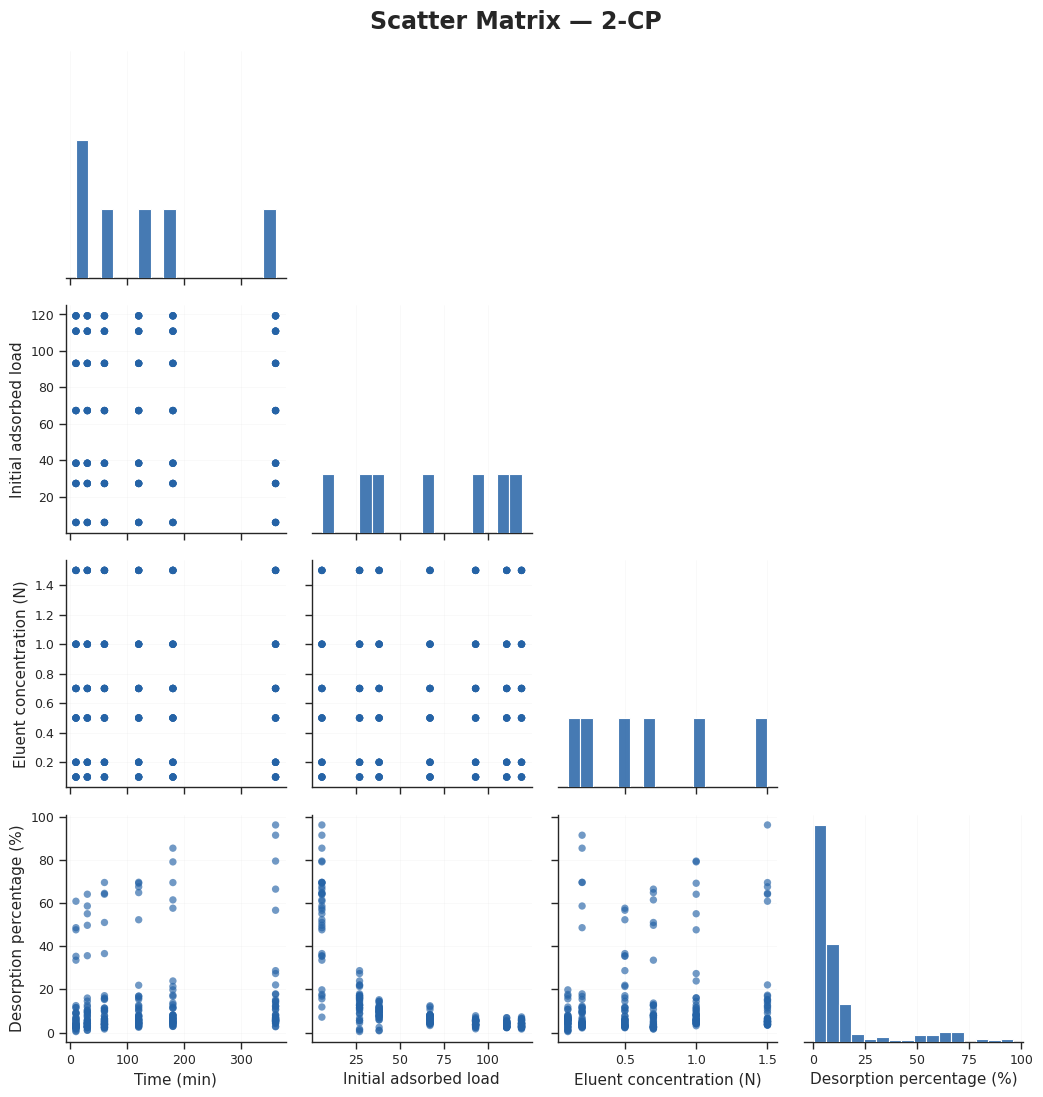

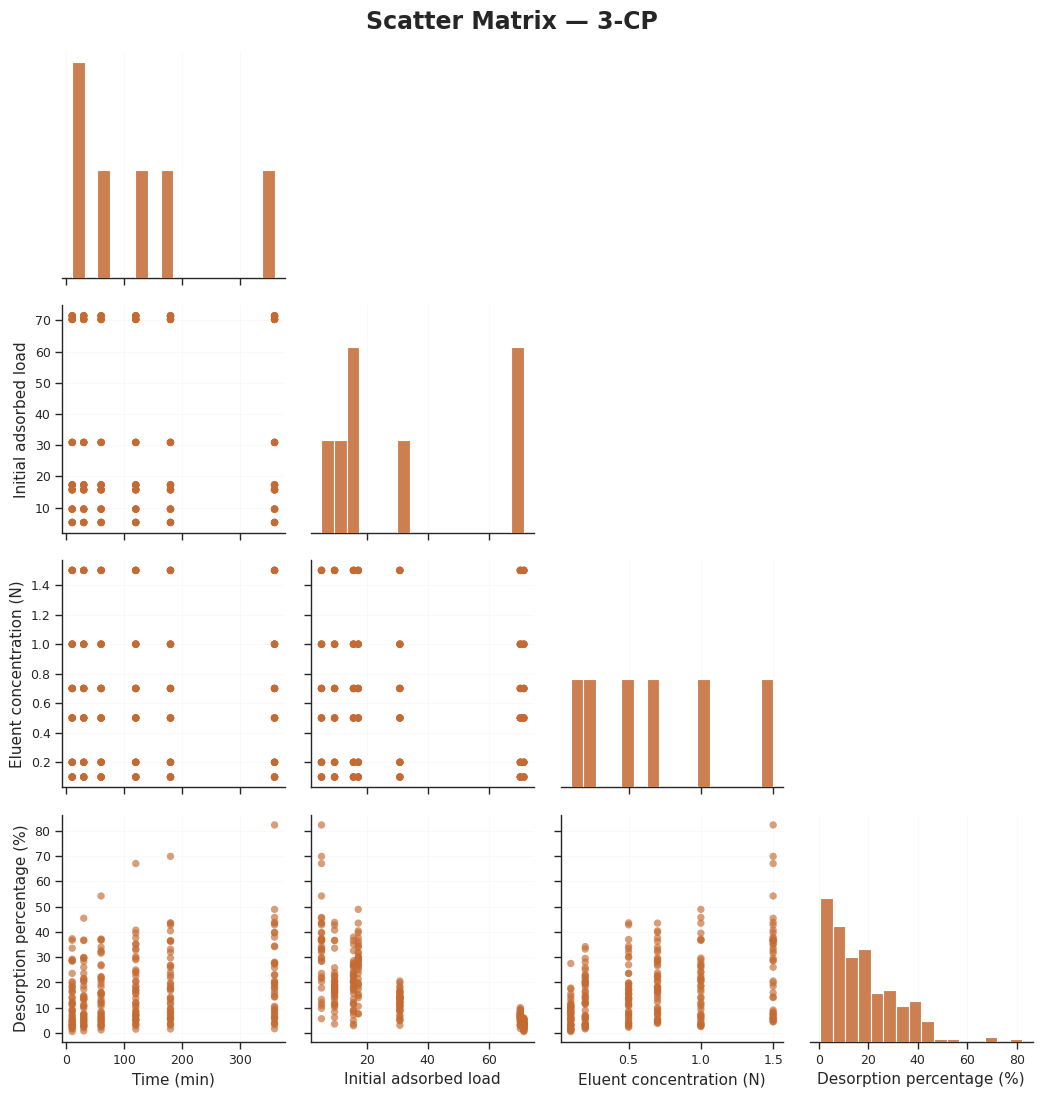

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style='ticks', context='paper', font_scale=1.3)
columns = ['Time', 'Initial adsorbed load', 'Eluent concentration', 'Desorption percentage']
labels = {'Time': 'Time (min)', 'Initial adsorbed load': 'Initial adsorbed load', 'Eluent concentration': 'Eluent concentration (N)', 'Desorption percentage': 'Desorption percentage (%)'}
for data, contaminant, color in [(df_2CP, '2-CP', '#2563A6'), (df_3CP, '3-CP', '#C46A32')]:
    subset = data[columns].rename(columns=labels)
    g = sns.pairplot(subset, corner=True, diag_kind='hist', height=2.7, aspect=1, plot_kws={'s':28, 'alpha':0.65, 'color':color, 'edgecolor':'none'}, diag_kws={'bins':16, 'color':color, 'edgecolor':'white', 'alpha':0.85})
    g.figure.suptitle(f'Scatter Matrix — {contaminant}', fontsize=17, fontweight='bold', y=1.02)
    for ax in g.axes.flat:
        if ax is not None:
            ax.tick_params(axis='both', labelsize=9)
            ax.grid(alpha=0.15, linewidth=0.5)
            ax.xaxis.label.set_size(11)
            ax.yaxis.label.set_size(11)
    g.figure.subplots_adjust(wspace=0.12, hspace=0.12)
    plt.show()


In [ ]:

import pandas as pd
import numpy as np
from IPython.display import display
columns = ['Time', 'Initial adsorbed load', 'Eluent concentration', 'Desorption percentage']
for data, contaminant in [(df_2CP, '2-CP'), (df_3CP, '3-CP')]:
    x = data[columns]
    stats = x.describe().T
    stats['Variance'] = x.var()
    stats['Skewness'] = x.skew()
    stats['Kurtosis'] = x.kurt()
    stats['CV (%)'] = (x.std() / x.mean()) * 100
    stats = stats.rename(columns={'count':'Count', 'mean':'Mean', 'std':'Std. deviation', 'min':'Minimum', '25%':'Q1 (25%)', '50%':'Median', '75%':'Q3 (75%)', 'max':'Maximum'})
    stats = stats[['Count', 'Mean', 'Std. deviation', 'Variance', 'Minimum', 'Q1 (25%)', 'Median', 'Q3 (75%)', 'Maximum', 'Skewness', 'Kurtosis', 'CV (%)']]
    print(f'\nDESCRIPTIVE STATISTICS — {contaminant}')
    display(stats.round(3))



DESCRIPTIVE STATISTICS — 2-CP


,Count,Mean,Std. deviation,Variance,Minimum,Q1 (25%),Median,Q3 (75%),Maximum,Skewness,Kurtosis,CV (%)
Time,252.0,126.667,119.073,14178.486,10.000,30.000,90.000,180.00,360.00,1.006,-0.253,94.005
Initial adsorbed load,252.0,65.965,40.578,1646.573,5.790,27.195,67.230,110.82,119.25,-0.077,-1.486,61.514
Eluent concentration,252.0,0.667,0.479,0.230,0.100,0.200,0.600,1.00,1.50,0.502,-0.940,71.906
Desorption percentage,252.0,13.617,18.974,360.008,0.427,4.104,6.125,11.90,96.20,2.467,5.282,139.339



DESCRIPTIVE STATISTICS — 3-CP


,Count,Mean,Std. deviation,Variance,Minimum,Q1 (25%),Median,Q3 (75%),Maximum,Skewness,Kurtosis,CV (%)
Time,252.0,126.667,119.073,14178.486,10.000,30.000,90.000,180.000,360.000,1.006,-0.253,94.005
Initial adsorbed load,252.0,31.465,26.048,678.482,5.212,9.495,17.250,70.300,71.451,0.712,-1.236,82.782
Eluent concentration,252.0,0.667,0.479,0.230,0.100,0.200,0.600,1.000,1.500,0.502,-0.940,71.906
Desorption percentage,252.0,17.561,13.613,185.316,0.581,6.372,14.312,26.148,82.252,1.251,2.235,77.519


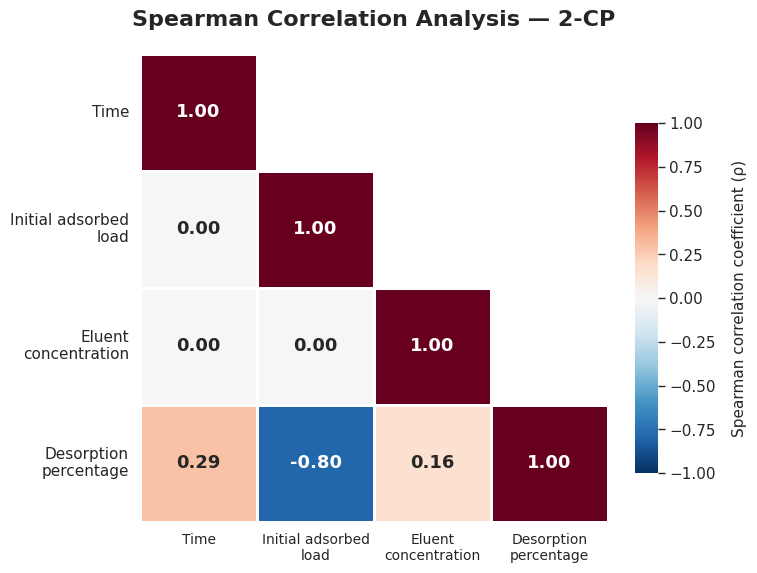

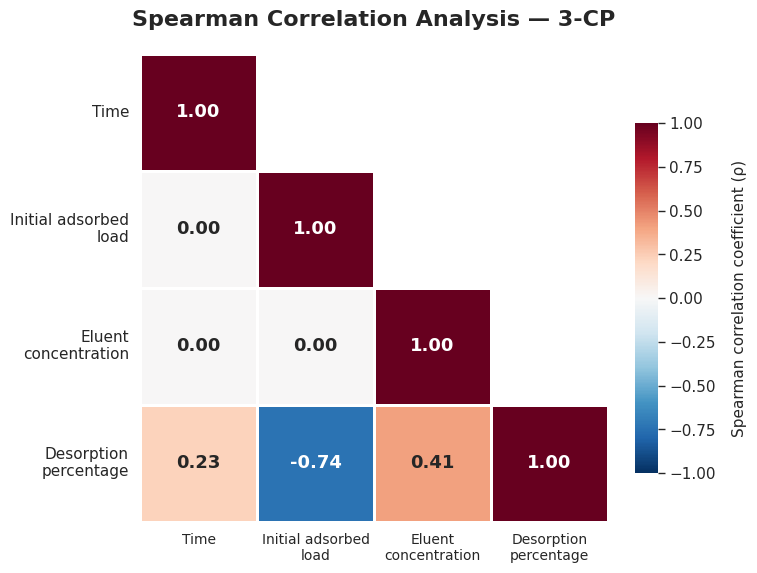

In [ ]:

import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
columns = ['Time', 'Initial adsorbed load', 'Eluent concentration', 'Desorption percentage']
labels = ['Time', 'Initial adsorbed\nload', 'Eluent\nconcentration', 'Desorption\npercentage']
sns.set_theme(style='white', context='paper', font_scale=1.25)
for data, contaminant in [(df_2CP, '2-CP'), (df_3CP, '3-CP')]:
    corr = data[columns].corr(method='spearman')
    corr.index = labels
    corr.columns = labels
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    fig, ax = plt.subplots(figsize=(9, 7))
    fig.subplots_adjust(left=0.30, right=0.82, bottom=0.20, top=0.87)
    cax = fig.add_axes([0.85, 0.27, 0.025, 0.50])
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0, square=True, linewidths=1, linecolor='white', annot_kws={'size':13, 'weight':'bold'}, cbar=True, cbar_ax=cax, ax=ax)
    ax.set_title(f'Spearman Correlation Analysis — {contaminant}', fontsize=16, fontweight='bold', pad=20)
    ax.set_xticklabels(labels, rotation=0, ha='center', fontsize=10)
    ax.set_yticklabels(labels, rotation=0, va='center', fontsize=11)
    ax.tick_params(axis='both', length=0, pad=8)
    ax.set_xlabel('')
    ax.set_ylabel('')
    cax.set_ylabel('Spearman correlation coefficient (ρ)', fontsize=11, labelpad=12)
    plt.show()


Total profiles: 42
Training profiles: 29
Testing profiles: 13
Training observations: 174
Testing observations: 78
Total hyperparameter combinations: 1024
Total cross-validation fits: 3072
Fitting 3 folds for each of 1024 candidates, totalling 3072 fits
BEST HYPERPARAMETERS: {'learning_rate': 0.07, 'max_depth': 4, 'min_samples_leaf': 7, 'n_estimators': 50, 'subsample': 0.4}
BEST MEAN CV RMSE (pp): 10.1153
COMPLETE HYPERPARAMETER OPTIMIZATION TABLE
Selection criterion: Lowest mean cross-validation RMSE


,n_estimators,learning_rate,max_depth,min_samples_leaf,subsample,Fold 1 RMSE (pp),Fold 2 RMSE (pp),Fold 3 RMSE (pp),Mean CV RMSE (pp),SD CV RMSE (pp),Rank,Selected
0,50,0.07,4,7,0.4,1.211700e+01,8.306900e+00,9.921900e+00,1.011530e+01,1.561500e+00,1,YES
1,50,0.07,7,7,0.4,1.211850e+01,8.306900e+00,9.922400e+00,1.011590e+01,1.562100e+00,2,
2,50,0.07,10,7,0.4,1.211850e+01,8.306900e+00,9.922400e+00,1.011590e+01,1.562100e+00,2,
3,100,0.07,7,7,0.4,1.375120e+01,7.191900e+00,9.972700e+00,1.030530e+01,2.688100e+00,4,
4,100,0.07,10,7,0.4,1.375120e+01,7.191900e+00,9.972700e+00,1.030530e+01,2.688100e+00,4,
...,...,...,...,...,...,...,...,...,...,...,...,...
1019,150,1.00,10,1,0.1,1.787880e+06,1.332344e+07,3.945849e+06,6.352389e+06,5.007385e+06,1020,
1020,150,1.00,7,1,0.1,2.315653e+06,2.485381e+07,8.762406e+06,1.197729e+07,9.477825e+06,1021,
1021,200,1.00,4,1,0.1,2.174928e+08,2.298146e+08,2.819260e+07,1.585000e+08,9.227846e+07,1022,
1022,200,1.00,10,1,0.1,7.910278e+07,3.734442e+08,3.687091e+08,2.737520e+08,1.376514e+08,1023,


BEST HYPERPARAMETER CONFIGURATION


,n_estimators,learning_rate,max_depth,min_samples_leaf,subsample,Fold 1 RMSE (pp),Fold 2 RMSE (pp),Fold 3 RMSE (pp),Mean CV RMSE (pp),SD CV RMSE (pp),Rank,Selected
0,50,0.07,4,7,0.4,12.117,8.3069,9.9219,10.1153,1.5615,1,YES


TOP 10 HYPERPARAMETER CONFIGURATIONS


,n_estimators,learning_rate,max_depth,min_samples_leaf,subsample,Fold 1 RMSE (pp),Fold 2 RMSE (pp),Fold 3 RMSE (pp),Mean CV RMSE (pp),SD CV RMSE (pp),Rank,Selected
0,50,0.07,4,7,0.4,12.1170,8.3069,9.9219,10.1153,1.5615,1,YES
1,50,0.07,7,7,0.4,12.1185,8.3069,9.9224,10.1159,1.5621,2,
2,50,0.07,10,7,0.4,12.1185,8.3069,9.9224,10.1159,1.5621,2,
3,100,0.07,7,7,0.4,13.7512,7.1919,9.9727,10.3053,2.6881,4,
4,100,0.07,10,7,0.4,13.7512,7.1919,9.9727,10.3053,2.6881,4,
5,100,0.07,4,7,0.4,13.7491,7.1966,9.9975,10.3144,2.6844,6,
6,200,0.04,4,7,0.4,13.8310,7.1268,10.2917,10.4165,2.7384,7,
7,200,0.04,7,7,0.4,13.8634,7.1268,10.2930,10.4278,2.7519,8,
8,200,0.04,10,7,0.4,13.8634,7.1268,10.2930,10.4278,2.7519,8,
9,150,0.04,4,7,0.4,13.4786,7.4181,10.5180,10.4716,2.4744,10,


... (4 outputs left out)

COMPLETE TESTING DATASET — 2-CP


,Time,Initial adsorbed load,Eluent concentration,Profile,Experimental desorption (%),Predicted desorption (%),Residual (pp),Absolute error (pp),Squared error
0,10,110.82,0.2,10,2.4192,3.0905,-0.6713,0.6713,0.4506
1,30,110.82,0.2,10,3.3018,3.8091,-0.5074,0.5074,0.2574
2,60,110.82,0.2,10,4.1599,4.1931,-0.0332,0.0332,0.0011
3,120,110.82,0.2,10,5.0189,4.9702,0.0487,0.0487,0.0024
4,180,110.82,0.2,10,5.0361,5.5244,-0.4883,0.4883,0.2385
...,...,...,...,...,...,...,...,...,...
73,30,119.25,1.5,41,3.3660,6.7673,-3.4013,3.4013,11.5686
74,60,119.25,1.5,41,3.5748,6.9394,-3.3646,3.3646,11.3204
75,120,119.25,1.5,41,3.9597,6.7078,-2.7480,2.7480,7.5516
76,180,119.25,1.5,41,4.2382,7.1987,-2.9606,2.9606,8.7651


TESTING PERFORMANCE BY EXPERIMENTAL CONDITION


,Dataset,n,R2,MSE,RMSE,MAE,Bias (pp)
0,Initial adsorbed load = 5.79,6,-0.1691,160.6691,12.6755,11.0394,-10.6139
1,Initial adsorbed load > 5.79,72,0.7769,7.2095,2.6850,1.7868,0.2481
2,Desorption ≥50%,5,-1.2412,192.4771,13.8736,12.9920,-12.9920


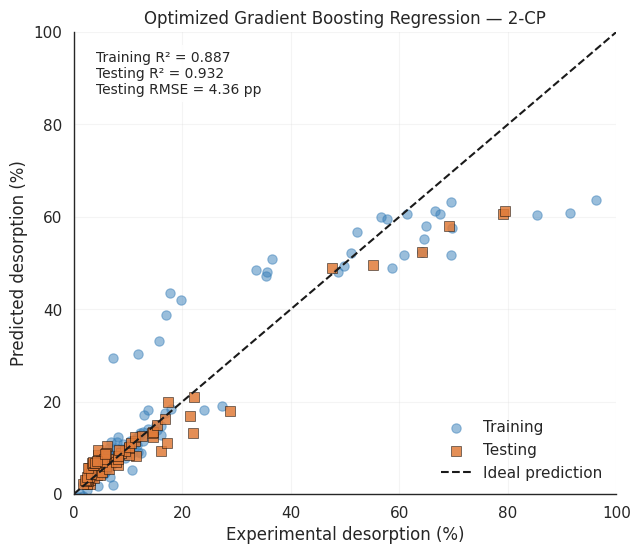

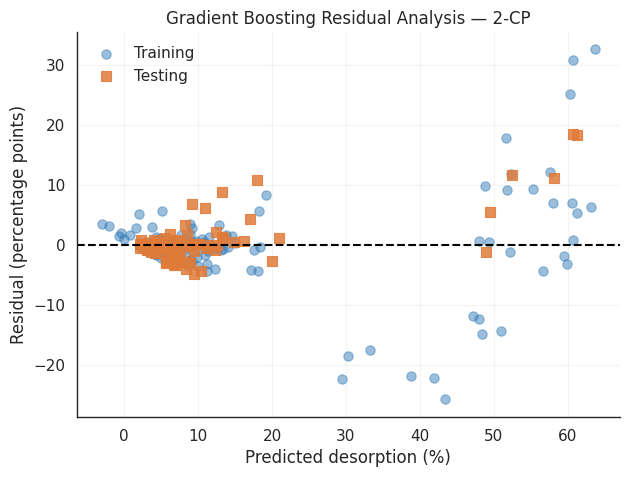

GRADIENT BOOSTING FEATURE IMPORTANCE — 2-CP


,Feature importance
Initial adsorbed load,0.8699
Eluent concentration,0.0708
Time,0.0593


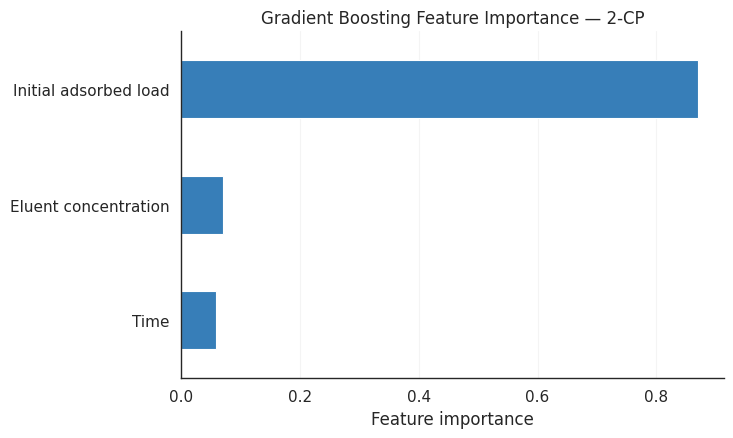

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import data_table, files
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, ParameterGrid
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
data = df_2CP.copy()
load_mapping = {5.79:10, 27.195:50, 38.32:100, 110.82:250, 67.23:500, 93.15:750, 119.25:1000}
data['Stratum'] = data['Initial adsorbed load'].round(3).map(load_mapping)
assert data['Stratum'].notna().all()
data['Profile'] = data.groupby(['Initial adsorbed load', 'Eluent concentration'], sort=False).ngroup()
features = ['Time', 'Initial adsorbed load', 'Eluent concentration']
X = data[features].copy()
y = data['Desorption percentage'].copy()
profiles = data[['Profile', 'Stratum']].drop_duplicates().reset_index(drop=True)
train_profiles, test_profiles = train_test_split(profiles['Profile'], test_size=0.30, random_state=42, stratify=profiles['Stratum'])
train_mask = data['Profile'].isin(train_profiles)
X_train, X_test = X.loc[train_mask], X.loc[~train_mask]
y_train, y_test = y.loc[train_mask], y.loc[~train_mask]
groups_train = data.loc[train_mask, 'Profile']
assert set(data.loc[train_mask, 'Profile']).isdisjoint(set(data.loc[~train_mask, 'Profile']))
print('Total profiles:', data['Profile'].nunique())
print('Training profiles:', len(train_profiles))
print('Testing profiles:', len(test_profiles))
print('Training observations:', len(X_train))
print('Testing observations:', len(X_test))
profile_cv = data.loc[train_mask, ['Profile', 'Stratum']].drop_duplicates().reset_index(drop=True)
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_splits = []
for tr, va in skf.split(profile_cv['Profile'], profile_cv['Stratum']):
    tr_ids = profile_cv.iloc[tr]['Profile']
    va_ids = profile_cv.iloc[va]['Profile']
    tr_idx = np.flatnonzero(groups_train.isin(tr_ids).to_numpy())
    va_idx = np.flatnonzero(groups_train.isin(va_ids).to_numpy())
    cv_splits.append((tr_idx, va_idx))
gbr = GradientBoostingRegressor(random_state=42)
param_grid = {
    'n_estimators': [50,100,150,200],
    'learning_rate': [0.01,0.04,0.07,1.0],
    'max_depth': [1,4,7,10],
    'min_samples_leaf': [1,4,7,10],
    'subsample': [0.1,0.4,0.7,1.0]
}
print('Total hyperparameter combinations:', len(ParameterGrid(param_grid)))
print('Total cross-validation fits:', len(ParameterGrid(param_grid))*len(cv_splits))
grid_search = GridSearchCV(gbr, param_grid, cv=cv_splits, scoring='neg_root_mean_squared_error', refit=True, n_jobs=-1, verbose=1, error_score='raise')
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
print('BEST HYPERPARAMETERS:', grid_search.best_params_)
print('BEST MEAN CV RMSE (pp):', round(-grid_search.best_score_,4))
r = pd.DataFrame(grid_search.cv_results_)
report = pd.DataFrame({
    'n_estimators': r['param_n_estimators'].astype(int),
    'learning_rate': r['param_learning_rate'].astype(float),
    'max_depth': r['param_max_depth'].astype(int),
    'min_samples_leaf': r['param_min_samples_leaf'].astype(int),
    'subsample': r['param_subsample'].astype(float)
})
for i in range(len(cv_splits)):
    report[f'Fold {i+1} RMSE (pp)'] = -r[f'split{i}_test_score'].to_numpy()
report['Mean CV RMSE (pp)'] = -r['mean_test_score'].to_numpy()
report['SD CV RMSE (pp)'] = r['std_test_score'].to_numpy()
report['Rank'] = r['rank_test_score'].to_numpy()
report['Selected'] = np.where(r.index == grid_search.best_index_,'YES','')
report = report.sort_values(['Rank','Selected','Mean CV RMSE (pp)'],ascending=[True,False,True]).reset_index(drop=True)
print('COMPLETE HYPERPARAMETER OPTIMIZATION TABLE')
print('Selection criterion: Lowest mean cross-validation RMSE')
display(data_table.DataTable(report.round(4),num_rows_per_page=20,include_index=False))
print('BEST HYPERPARAMETER CONFIGURATION')
display(report[report['Selected']=='YES'].round(4))
print('TOP 10 HYPERPARAMETER CONFIGURATIONS')
display(report.head(10).round(4))
report.to_csv('GradientBoosting_2CP_AdsorbedLoad_Hyperparameter_Optimization.csv',index=False)
fold_rmse = [-r.loc[grid_search.best_index_,f'split{i}_test_score'] for i in range(len(cv_splits))]
fold_results = pd.DataFrame({'Fold':range(1,len(cv_splits)+1),'RMSE (pp)':fold_rmse})
print('BEST MODEL: CROSS-VALIDATION PERFORMANCE')
display(fold_results.round(4))
print('Mean CV RMSE (pp):',round(np.mean(fold_rmse),4))
print('CV RMSE standard deviation (pp):',round(np.std(fold_rmse,ddof=0),4))
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)
def evaluate(actual,predicted,name):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    mse = mean_squared_error(actual,predicted)
    return {'Dataset':name,'n':len(actual),'R2':r2_score(actual,predicted),'MSE':mse,'RMSE':np.sqrt(mse),'MAE':mean_absolute_error(actual,predicted),'Bias (pp)':np.mean(predicted-actual)}
results = pd.DataFrame([evaluate(y_train,y_train_pred,'Training'),evaluate(y_test,y_test_pred,'Testing')])
print('FINAL GRADIENT BOOSTING REGRESSION PERFORMANCE — 2-CP')
display(results.round(4))
test_results = X_test.copy()
test_results['Profile'] = data.loc[~train_mask,'Profile'].to_numpy()
test_results['Experimental desorption (%)'] = y_test.to_numpy()
test_results['Predicted desorption (%)'] = y_test_pred
test_results['Residual (pp)'] = test_results['Experimental desorption (%)']-test_results['Predicted desorption (%)']
test_results['Absolute error (pp)'] = test_results['Residual (pp)'].abs()
test_results['Squared error'] = test_results['Residual (pp)']**2
test_results = test_results.sort_values(['Profile','Time']).reset_index(drop=True)
print('COMPLETE TESTING DATASET — 2-CP')
display(data_table.DataTable(test_results.round(4),num_rows_per_page=20,include_index=False))
subgroup_results = []
for label, condition in [('Initial adsorbed load = 5.79',X_test['Initial adsorbed load'].round(3)==5.79),('Initial adsorbed load > 5.79',X_test['Initial adsorbed load'].round(3)>5.79),('Desorption ≥50%',y_test>=50)]:
    if condition.sum()>1:
        subgroup_results.append(evaluate(y_test.loc[condition],y_test_pred[condition.to_numpy()],label))
print('TESTING PERFORMANCE BY EXPERIMENTAL CONDITION')
display(pd.DataFrame(subgroup_results).round(4))
plt.rcParams.update({'font.size':12,'axes.spines.top':False,'axes.spines.right':False})
fig,ax = plt.subplots(figsize=(7,6))
ax.scatter(y_train,y_train_pred,s=45,alpha=0.5,color='#377eb8',label='Training')
ax.scatter(y_test,y_test_pred,s=60,alpha=0.85,marker='s',color='#e07b39',edgecolor='black',linewidth=0.4,label='Testing')
ax.plot([0,100],[0,100],'k--',linewidth=1.5,label='Ideal prediction')
ax.set(xlabel='Experimental desorption (%)',ylabel='Predicted desorption (%)',title='Optimized Gradient Boosting Regression — 2-CP',xlim=(0,100),ylim=(0,100))
ax.text(0.04,0.96,f'Training R² = {results.loc[0,"R2"]:.3f}\nTesting R² = {results.loc[1,"R2"]:.3f}\nTesting RMSE = {results.loc[1,"RMSE"]:.2f} pp',transform=ax.transAxes,va='top',fontsize=10,bbox={'facecolor':'white','alpha':0.85,'edgecolor':'none'})
ax.legend(frameon=False,loc='lower right')
ax.grid(alpha=0.2)
plt.show()
fig,ax = plt.subplots(figsize=(7,5))
ax.scatter(y_train_pred,y_train.to_numpy()-y_train_pred,s=45,alpha=0.5,color='#377eb8',label='Training')
ax.scatter(y_test_pred,y_test.to_numpy()-y_test_pred,s=60,alpha=0.85,marker='s',color='#e07b39',label='Testing')
ax.axhline(0,color='black',linestyle='--',linewidth=1.5)
ax.set(xlabel='Predicted desorption (%)',ylabel='Residual (percentage points)',title='Gradient Boosting Residual Analysis — 2-CP')
ax.legend(frameon=False)
ax.grid(alpha=0.2)
plt.show()
importance = pd.Series(best_model.feature_importances_,index=features).sort_values()
print('GRADIENT BOOSTING FEATURE IMPORTANCE — 2-CP')
display(importance.sort_values(ascending=False).to_frame('Feature importance').round(4))
fig,ax = plt.subplots(figsize=(7,4.5))
importance.plot.barh(ax=ax,color='#377eb8')
ax.set(xlabel='Feature importance',title='Gradient Boosting Feature Importance — 2-CP')
ax.grid(axis='x',alpha=0.2)
plt.show()


Total profiles: 42
Training profiles: 29
Testing profiles: 13
Training observations: 174
Testing observations: 78
Total hyperparameter combinations: 1024
Total cross-validation fits: 3072
Fitting 3 folds for each of 1024 candidates, totalling 3072 fits
BEST HYPERPARAMETERS: {'learning_rate': 0.07, 'max_depth': 4, 'min_samples_leaf': 4, 'n_estimators': 200, 'subsample': 0.4}
BEST MEAN CV RMSE (pp): 6.8131
COMPLETE HYPERPARAMETER OPTIMIZATION TABLE
Selection criterion: Lowest mean cross-validation RMSE


,n_estimators,learning_rate,max_depth,min_samples_leaf,subsample,Fold 1 RMSE (pp),Fold 2 RMSE (pp),Fold 3 RMSE (pp),Mean CV RMSE (pp),SD CV RMSE (pp),Rank,Selected
0,200,0.07,4,4,0.4,5.737400e+00,1.036420e+01,4.337900e+00,6.813100e+00,2.575100e+00,1,YES
1,150,0.07,4,4,0.4,5.646200e+00,1.047400e+01,4.640800e+00,6.920300e+00,2.546100e+00,2,
2,200,0.07,10,4,0.4,5.792400e+00,1.053540e+01,4.556400e+00,6.961400e+00,2.577100e+00,3,
3,100,0.07,4,4,0.4,5.835500e+00,1.059600e+01,4.452700e+00,6.961400e+00,2.631300e+00,4,
4,200,0.07,7,4,0.4,5.792400e+00,1.053540e+01,4.660200e+00,6.996000e+00,2.545100e+00,5,
...,...,...,...,...,...,...,...,...,...,...,...,...
1019,150,1.00,10,1,0.1,2.735338e+06,6.023566e+06,3.665307e+06,4.141404e+06,1.383982e+06,1020,
1020,150,1.00,4,1,0.1,5.384755e+05,3.587475e+07,2.573686e+06,1.299564e+07,1.619930e+07,1021,
1021,200,1.00,7,1,0.1,9.761420e+07,2.907063e+08,1.625183e+08,1.836129e+08,8.022834e+07,1022,
1022,200,1.00,10,1,0.1,9.921972e+07,2.342831e+08,2.349626e+08,1.894885e+08,6.383026e+07,1023,


BEST HYPERPARAMETER CONFIGURATION


,n_estimators,learning_rate,max_depth,min_samples_leaf,subsample,Fold 1 RMSE (pp),Fold 2 RMSE (pp),Fold 3 RMSE (pp),Mean CV RMSE (pp),SD CV RMSE (pp),Rank,Selected
0,200,0.07,4,4,0.4,5.7374,10.3642,4.3379,6.8131,2.5751,1,YES


TOP 10 HYPERPARAMETER CONFIGURATIONS


,n_estimators,learning_rate,max_depth,min_samples_leaf,subsample,Fold 1 RMSE (pp),Fold 2 RMSE (pp),Fold 3 RMSE (pp),Mean CV RMSE (pp),SD CV RMSE (pp),Rank,Selected
0,200,0.07,4,4,0.4,5.7374,10.3642,4.3379,6.8131,2.5751,1,YES
1,150,0.07,4,4,0.4,5.6462,10.4740,4.6408,6.9203,2.5461,2,
2,200,0.07,10,4,0.4,5.7924,10.5354,4.5564,6.9614,2.5771,3,
3,100,0.07,4,4,0.4,5.8355,10.5960,4.4527,6.9614,2.6313,4,
4,200,0.07,7,4,0.4,5.7924,10.5354,4.6602,6.9960,2.5451,5,
5,150,0.07,7,4,0.4,5.7545,10.6164,4.6475,7.0061,2.5926,6,
6,150,0.07,10,4,0.4,5.7545,10.6164,4.6483,7.0064,2.5923,7,
7,100,0.07,4,1,1.0,5.9982,10.9646,4.0825,7.0151,2.9002,8,
8,150,0.04,4,1,1.0,6.0613,10.9591,4.1166,7.0457,2.8788,9,
9,100,0.07,7,4,0.4,5.9397,10.7629,4.4954,7.0660,2.6798,10,


... (4 outputs left out)

COMPLETE TESTING DATASET — 3-CP


,Time,Initial adsorbed load,Eluent concentration,Profile,Experimental desorption (%),Predicted desorption (%),Residual (pp),Absolute error (pp),Squared error
0,10,15.68,0.2,10,8.9477,9.8250,-0.8773,0.8773,0.7697
1,30,15.68,0.2,10,11.3584,11.8260,-0.4676,0.4676,0.2186
2,60,15.68,0.2,10,12.0663,13.9787,-1.9124,1.9124,3.6573
3,120,15.68,0.2,10,20.3316,15.9269,4.4047,4.4047,19.4015
4,180,15.68,0.2,10,22.7934,16.6984,6.0950,6.0950,37.1487
...,...,...,...,...,...,...,...,...,...
73,30,17.25,1.5,41,29.5826,30.4610,-0.8784,0.8784,0.7717
74,60,17.25,1.5,41,31.5710,35.3142,-3.7432,3.7432,14.0117
75,120,17.25,1.5,41,35.1826,40.0534,-4.8708,4.8708,23.7250
76,180,17.25,1.5,41,36.3130,42.2777,-5.9646,5.9646,35.5768


TESTING PERFORMANCE BY EXPERIMENTAL CONDITION


,Dataset,n,R2,MSE,RMSE,MAE,Bias (pp)
0,Initial adsorbed load = 5.212,6,-1.7036,33.5061,5.7884,4.5753,-2.8295
1,Initial adsorbed load > 5.212,72,0.8980,16.3622,4.0450,3.0886,-0.0546


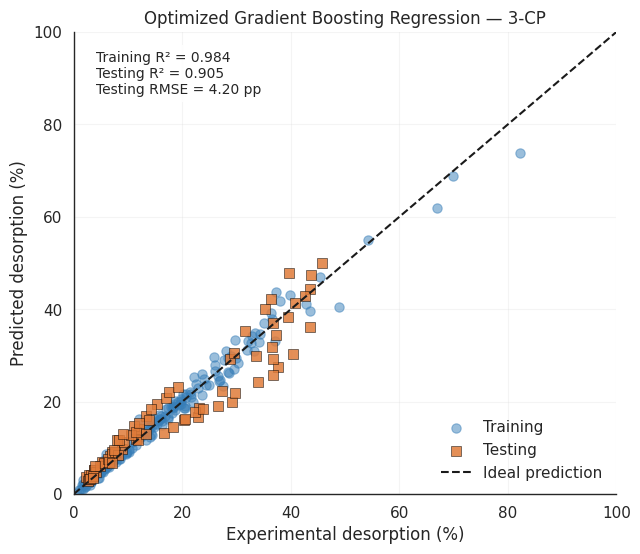

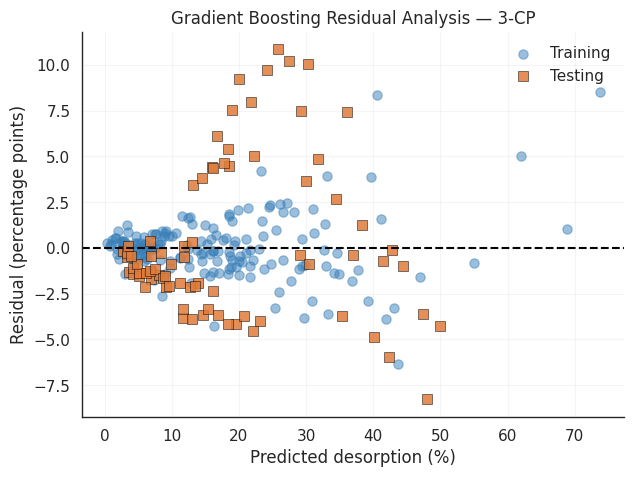

GRADIENT BOOSTING FEATURE IMPORTANCE — 3-CP


,Feature importance
Initial adsorbed load,0.5134
Eluent concentration,0.3435
Time,0.1431


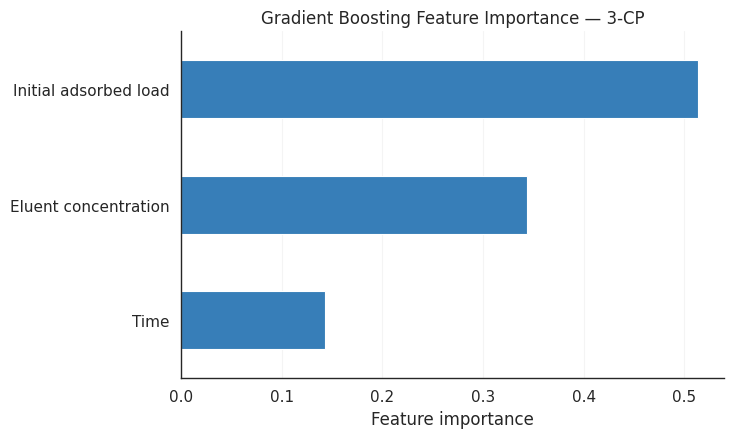

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import data_table, files
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, ParameterGrid
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
data = df_3CP.copy()
load_mapping = {5.212:10, 9.495:50, 71.451:100, 15.68:250, 30.87:500, 70.3:750, 17.25:1000}
data['Stratum'] = data['Initial adsorbed load'].round(3).map(load_mapping)
assert data['Stratum'].notna().all()
data['Profile'] = data.groupby(['Initial adsorbed load', 'Eluent concentration'], sort=False).ngroup()
features = ['Time', 'Initial adsorbed load', 'Eluent concentration']
X = data[features].copy()
y = data['Desorption percentage'].copy()
profiles = data[['Profile', 'Stratum']].drop_duplicates().reset_index(drop=True)
train_profiles, test_profiles = train_test_split(profiles['Profile'], test_size=0.30, random_state=42, stratify=profiles['Stratum'])
train_mask = data['Profile'].isin(train_profiles)
X_train, X_test = X.loc[train_mask], X.loc[~train_mask]
y_train, y_test = y.loc[train_mask], y.loc[~train_mask]
groups_train = data.loc[train_mask, 'Profile']
assert set(data.loc[train_mask, 'Profile']).isdisjoint(set(data.loc[~train_mask, 'Profile']))
print('Total profiles:', data['Profile'].nunique())
print('Training profiles:', len(train_profiles))
print('Testing profiles:', len(test_profiles))
print('Training observations:', len(X_train))
print('Testing observations:', len(X_test))
profile_cv = data.loc[train_mask, ['Profile', 'Stratum']].drop_duplicates().reset_index(drop=True)
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_splits = []
for tr, va in skf.split(profile_cv['Profile'], profile_cv['Stratum']):
    tr_ids = profile_cv.iloc[tr]['Profile']
    va_ids = profile_cv.iloc[va]['Profile']
    tr_idx = np.flatnonzero(groups_train.isin(tr_ids).to_numpy())
    va_idx = np.flatnonzero(groups_train.isin(va_ids).to_numpy())
    cv_splits.append((tr_idx, va_idx))
gbr = GradientBoostingRegressor(random_state=42)
param_grid = {
    'n_estimators': [50,100,150,200],
    'learning_rate': [0.01,0.04,0.07,1.0],
    'max_depth': [1,4,7,10],
    'min_samples_leaf': [1,4,7,10],
    'subsample': [0.1,0.4,0.7,1.0]
}
print('Total hyperparameter combinations:', len(ParameterGrid(param_grid)))
print('Total cross-validation fits:', len(ParameterGrid(param_grid))*len(cv_splits))
grid_search = GridSearchCV(gbr, param_grid, cv=cv_splits, scoring='neg_root_mean_squared_error', refit=True, n_jobs=-1, verbose=1, error_score='raise')
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
print('BEST HYPERPARAMETERS:', grid_search.best_params_)
print('BEST MEAN CV RMSE (pp):', round(-grid_search.best_score_,4))
r = pd.DataFrame(grid_search.cv_results_)
report = pd.DataFrame({
    'n_estimators': r['param_n_estimators'].astype(int),
    'learning_rate': r['param_learning_rate'].astype(float),
    'max_depth': r['param_max_depth'].astype(int),
    'min_samples_leaf': r['param_min_samples_leaf'].astype(int),
    'subsample': r['param_subsample'].astype(float)
})
for i in range(len(cv_splits)):
    report[f'Fold {i+1} RMSE (pp)'] = -r[f'split{i}_test_score'].to_numpy()
report['Mean CV RMSE (pp)'] = -r['mean_test_score'].to_numpy()
report['SD CV RMSE (pp)'] = r['std_test_score'].to_numpy()
report['Rank'] = r['rank_test_score'].to_numpy()
report['Selected'] = np.where(r.index == grid_search.best_index_,'YES','')
report = report.sort_values(['Rank','Selected','Mean CV RMSE (pp)'],ascending=[True,False,True]).reset_index(drop=True)
print('COMPLETE HYPERPARAMETER OPTIMIZATION TABLE')
print('Selection criterion: Lowest mean cross-validation RMSE')
display(data_table.DataTable(report.round(4),num_rows_per_page=20,include_index=False))
print('BEST HYPERPARAMETER CONFIGURATION')
display(report[report['Selected']=='YES'].round(4))
print('TOP 10 HYPERPARAMETER CONFIGURATIONS')
display(report.head(10).round(4))
report.to_csv('GradientBoosting_3CP_AdsorbedLoad_Hyperparameter_Optimization.csv',index=False)
fold_rmse = [-r.loc[grid_search.best_index_,f'split{i}_test_score'] for i in range(len(cv_splits))]
fold_results = pd.DataFrame({'Fold':range(1,len(cv_splits)+1),'RMSE (pp)':fold_rmse})
print('BEST MODEL: CROSS-VALIDATION PERFORMANCE')
display(fold_results.round(4))
print('Mean CV RMSE (pp):',round(np.mean(fold_rmse),4))
print('CV RMSE standard deviation (pp):',round(np.std(fold_rmse,ddof=0),4))
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)
def evaluate(actual,predicted,name):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    mse = mean_squared_error(actual,predicted)
    return {'Dataset':name,'n':len(actual),'R2':r2_score(actual,predicted),'MSE':mse,'RMSE':np.sqrt(mse),'MAE':mean_absolute_error(actual,predicted),'Bias (pp)':np.mean(predicted-actual)}
results = pd.DataFrame([evaluate(y_train,y_train_pred,'Training'),evaluate(y_test,y_test_pred,'Testing')])
print('FINAL GRADIENT BOOSTING REGRESSION PERFORMANCE — 3-CP')
display(results.round(4))
test_results = X_test.copy()
test_results['Profile'] = data.loc[~train_mask,'Profile'].to_numpy()
test_results['Experimental desorption (%)'] = y_test.to_numpy()
test_results['Predicted desorption (%)'] = y_test_pred
test_results['Residual (pp)'] = test_results['Experimental desorption (%)']-test_results['Predicted desorption (%)']
test_results['Absolute error (pp)'] = test_results['Residual (pp)'].abs()
test_results['Squared error'] = test_results['Residual (pp)']**2
test_results = test_results.sort_values(['Profile','Time']).reset_index(drop=True)
print('COMPLETE TESTING DATASET — 3-CP')
display(data_table.DataTable(test_results.round(4),num_rows_per_page=20,include_index=False))
subgroup_results = []
for label, condition in [('Initial adsorbed load = 5.212',X_test['Initial adsorbed load'].round(3)==5.212),('Initial adsorbed load > 5.212',X_test['Initial adsorbed load'].round(3)>5.212),('Desorption ≥50%',y_test>=50)]:
    if condition.sum()>1:
        subgroup_results.append(evaluate(y_test.loc[condition],y_test_pred[condition.to_numpy()],label))
print('TESTING PERFORMANCE BY EXPERIMENTAL CONDITION')
display(pd.DataFrame(subgroup_results).round(4))
plt.rcParams.update({'font.size':12,'axes.spines.top':False,'axes.spines.right':False})
fig,ax = plt.subplots(figsize=(7,6))
ax.scatter(y_train,y_train_pred,s=45,alpha=0.5,color='#377eb8',label='Training')
ax.scatter(y_test,y_test_pred,s=60,alpha=0.85,marker='s',color='#e07b39',edgecolor='black',linewidth=0.4,label='Testing')
ax.plot([0,100],[0,100],'k--',linewidth=1.5,label='Ideal prediction')
ax.set(xlabel='Experimental desorption (%)',ylabel='Predicted desorption (%)',title='Optimized Gradient Boosting Regression — 3-CP',xlim=(0,100),ylim=(0,100))
ax.text(0.04,0.96,f'Training R² = {results.loc[0,"R2"]:.3f}\nTesting R² = {results.loc[1,"R2"]:.3f}\nTesting RMSE = {results.loc[1,"RMSE"]:.2f} pp',transform=ax.transAxes,va='top',fontsize=10,bbox={'facecolor':'white','alpha':0.85,'edgecolor':'none'})
ax.legend(frameon=False,loc='lower right')
ax.grid(alpha=0.2)
plt.show()
fig,ax = plt.subplots(figsize=(7,5))
ax.scatter(y_train_pred,y_train.to_numpy()-y_train_pred,s=45,alpha=0.5,color='#377eb8',label='Training')
ax.scatter(y_test_pred,y_test.to_numpy()-y_test_pred,s=60,alpha=0.85,marker='s',color='#e07b39',edgecolor='black',linewidth=0.4,label='Testing')
ax.axhline(0,color='black',linestyle='--',linewidth=1.5)
ax.set(xlabel='Predicted desorption (%)',ylabel='Residual (percentage points)',title='Gradient Boosting Residual Analysis — 3-CP')
ax.legend(frameon=False)
ax.grid(alpha=0.2)
plt.show()
importance = pd.Series(best_model.feature_importances_,index=features).sort_values()
print('GRADIENT BOOSTING FEATURE IMPORTANCE — 3-CP')
display(importance.sort_values(ascending=False).to_frame('Feature importance').round(4))
fig,ax = plt.subplots(figsize=(7,4.5))
importance.plot.barh(ax=ax,color='#377eb8')
ax.set(xlabel='Feature importance',title='Gradient Boosting Feature Importance — 3-CP')
ax.grid(axis='x',alpha=0.2)
plt.show()
